In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, MinMaxScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

In [3]:
df_train= pd.read_csv("train.csv")
df_test= pd.read_csv("test.csv")
df_val= pd.read_csv("validation.csv")

In [4]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 914 entries, 0 to 913
Data columns (total 15 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   sample_id  914 non-null    object 
 1   B1         914 non-null    float64
 2   B2         914 non-null    float64
 3   B3         914 non-null    float64
 4   B4         914 non-null    float64
 5   B5         914 non-null    float64
 6   B6         914 non-null    float64
 7   B7         914 non-null    float64
 8   B8         914 non-null    float64
 9   B8A        914 non-null    float64
 10  B9         914 non-null    float64
 11  B11        914 non-null    float64
 12  B12        914 non-null    float64
 13  NDVI       914 non-null    float64
 14  target     914 non-null    object 
dtypes: float64(13), object(2)
memory usage: 107.2+ KB


In [5]:
df_train.describe()

,B1,B2,B3,B4,B5,B6,B7,B8,B8A,B9,B11,B12,NDVI
count,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000,914.000000
mean,724.602978,765.024342,1080.519307,1309.674616,1787.972449,2657.614845,2969.830246,3164.291911,3271.462008,3311.769682,3194.277218,2346.057529,0.399936
std,442.574491,467.771476,459.256468,590.215200,577.360668,841.381910,982.261043,1041.631446,1002.194699,960.021292,768.301595,845.404473,0.186436
min,163.651798,114.434772,152.293584,121.702337,204.284964,254.421420,289.542959,310.531086,334.595406,387.504645,403.149069,264.151089,0.050905
25%,569.136845,584.838142,881.470435,940.718982,1444.694603,2130.786723,2338.708566,2465.274889,2615.790948,2745.394650,2810.106921,1818.794245,0.268579
50%,656.822568,736.268744,1045.817299,1313.457818,1756.060715,2592.414491,2869.311349,3081.867065,3236.415031,3323.149425,3116.003152,2159.766057,0.320749
75%,788.560258,848.456918,1189.268053,1617.013014,2074.876490,3166.538892,3572.058894,3799.885919,3898.627396,3904.292048,3523.523442,2816.859062,0.515869
max,5709.965409,6294.211246,6163.090339,6234.293943,6561.704046,6538.004103,6468.502051,6895.525380,6651.823331,9478.866175,6899.265565,5978.137917,0.886649


In [6]:
df_train.isnull().sum()

,0
sample_id,0
B1,0
B2,0
B3,0
B4,0
B5,0
B6,0
B7,0
B8,0
B8A,0


In [7]:
#Find Identical columns
def identicalcols(df):
    identical_cols = []
    cols = df.columns
    for i in range(len(cols)):
        for j in range(i + 1, len(cols)):
            if df[cols[i]].equals(df[cols[j]]):
                identical_cols.append((cols[i], cols[j]))
    return identical_cols

duplicates = identicalcols(df_train)

if duplicates:
    print("Identical columns:")
    for pair in duplicates:
        print(f"{pair[0]} == {pair[1]}")
else:
    print("No identical columns.")

No identical columns.


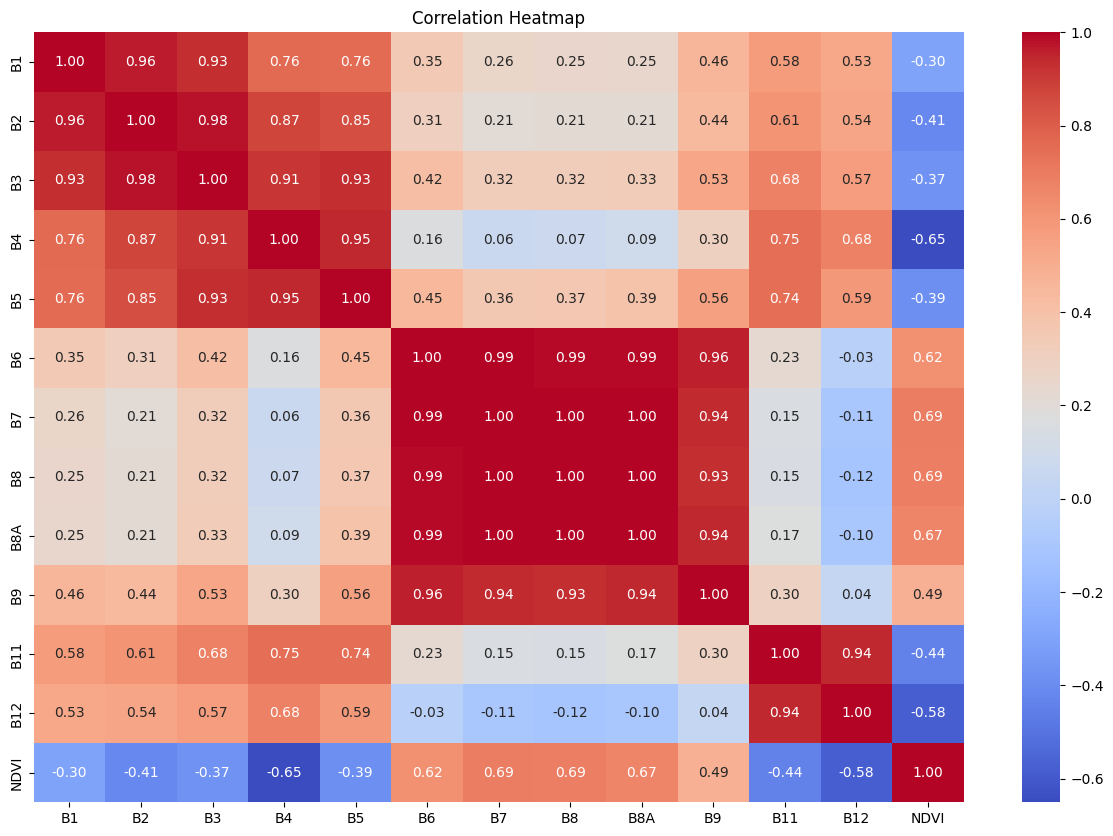

In [8]:
numeric_df = df_train.select_dtypes(include=['number'])
correlated_data = numeric_df.corr()
plt.figure(figsize=(15, 10))
sns.heatmap(correlated_data, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [9]:
import pandas as pd

datasets = {
    "Train": "train.csv",
    "Validation": "validation.csv",
    "Test": "test.csv"
}

for split, path in datasets.items():
    df = pd.read_csv(path)

    print(f"\n{'='*40}")
    print(f"{split} distribution")
    print('='*40)

    if "target" in df.columns:
        counts = df["target"].value_counts()
        percentages = df["target"].value_counts(normalize=True) * 100

        distribution = pd.DataFrame({
            "Count": counts,
            "Percentage (%)": percentages.round(2)
        })

        print(distribution)
        print("Imbalance ratio:",
              round(counts.max() / counts.min(), 2))
    else:
        print("No target labels available.")


Train distribution
         Count  Percentage (%)
target                        
wheat      425           46.50
alfalfa    247           27.02
maize      242           26.48
Imbalance ratio: 1.76

Validation distribution
         Count  Percentage (%)
target                        
wheat       50           33.33
maize       50           33.33
alfalfa     50           33.33
Imbalance ratio: 1.0

Test distribution
No target labels available.


In [10]:
seeds = [0, 1, 2]
pca_components = 8
n_qubits = 4

# **Classical Baseline**

In [11]:
from sklearn.preprocessing import LabelEncoder

df_train = pd.read_csv("train.csv")

# Define the feature columns present in the dataset (excluding identifier and target)
feature_columns = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']

X_train = df_train[feature_columns].to_numpy(dtype=float)
X_test = df_test[feature_columns].to_numpy(dtype=float)
X_val = df_val[feature_columns].to_numpy(dtype=float)

# Target: Use the categorical crop type column for classification
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train['target'].values)
y_val = label_encoder.transform(df_val['target'].values)

# Definig the model's pipeline
pipeline = Pipeline([
    ("scaler", MinMaxScaler()),                       # Normalize features
    ("pca", PCA(n_components=pca_components)),
    ("classifier", SVC(kernel="rbf", C=1.0, gamma="scale")) # SVM classifier
])


==================== BASELINE TRAINING CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.90      0.93      0.91       247
       maize       0.87      0.93      0.90       242
       wheat       0.92      0.87      0.90       425

    accuracy                           0.90       914
   macro avg       0.90      0.91      0.90       914
weighted avg       0.90      0.90      0.90       914


==================== BASELINE VALIDATION CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.89      0.94      0.91        50
       maize       0.84      0.84      0.84        50
       wheat       0.81      0.76      0.78        50

    accuracy                           0.85       150
   macro avg       0.85      0.85      0.85       150
weighted avg       0.85      0.85      0.85       150



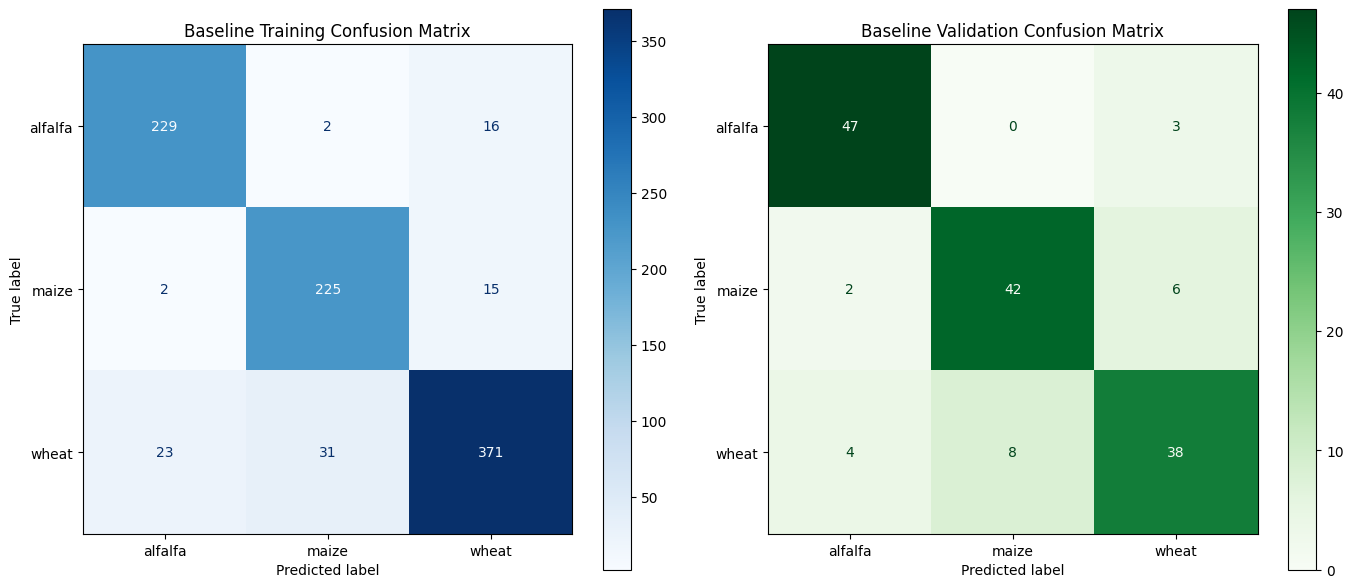


==================== BASELINE TEST SET PREDICTIONS ====================


,sample_id,predicted_target
0,r2_20ee84e282b608b9,maize
1,r2_3f59edc42ae9243f,maize
2,r2_40d69d894813f204,wheat
3,r2_278ee6f93f7b31ef,maize
4,r2_653d9a22fd070481,maize
5,r2_7fbb4905ffbf8d7e,maize
6,r2_e261f65f34789124,alfalfa
7,r2_53bebc7590cf779d,maize
8,r2_ee7d113fc7f4c99e,maize
9,r2_b01ab6e02585518e,maize


In [12]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd

# 1. Fit the baseline pipeline on the training data first
pipeline.fit(X_train, y_train)

# 2. Generate predictions using the fitted baseline pipeline
train_pred_baseline = pipeline.predict(X_train)
val_pred_baseline = pipeline.predict(X_val)
test_pred_baseline = pipeline.predict(X_test)

# Retrieve target class names from the LabelEncoder
target_names = list(label_encoder.classes_)

# --- Baseline Evaluation Reports ---
print("\n" + "="*20 + " BASELINE TRAINING CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_train, train_pred_baseline, target_names=target_names))

print("\n" + "="*20 + " BASELINE VALIDATION CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_val, val_pred_baseline, target_names=target_names))

# --- Confusion Matrices Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Train Confusion Matrix
cm_train = confusion_matrix(y_train, train_pred_baseline)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=target_names)
disp_train.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Baseline Training Confusion Matrix")

# Validation Confusion Matrix
cm_val = confusion_matrix(y_val, val_pred_baseline)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=target_names)
disp_val.plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Baseline Validation Confusion Matrix")

plt.tight_layout()
plt.show()

# --- Baseline Test Set Predictions ---
print("\n" + "="*20 + " BASELINE TEST SET PREDICTIONS " + "="*20)
test_pred_labels_baseline = label_encoder.inverse_transform(test_pred_baseline)
df_test_results_baseline = pd.DataFrame({
    'sample_id': df_test['sample_id'],
    'predicted_target': test_pred_labels_baseline
})
display(df_test_results_baseline.head(10))

In [13]:
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

val_accuracies = []
baseline_f1 = []

# Evaluate the Classical Baseline over the different seeds
for seed in seeds:
    print(f"Evaluating Seed {seed}...")

    # Update the classifier's random state if it supports one
    if hasattr(pipeline.named_steps["classifier"], "random_state"):
        pipeline.named_steps["classifier"].random_state = seed

    pipeline.fit(X_train, y_train)

    # Predict & evaluate on validation set
    val_pred_seed = pipeline.predict(X_val)

    acc = accuracy_score(y_val, val_pred_seed)
    f1 = f1_score(y_val, val_pred_seed, average='weighted')

    val_accuracies.append(acc)
    baseline_f1.append(f1)
    print(f"Seed {seed} | Validation Accuracy: {acc:.4f} | Validation F1: {f1:.4f}")

print("\n" + "="*20 + " MULTI-SEED METRICS SUMMARY " + "="*20)
print(f"Validation Accuracy: {np.mean(val_accuracies):.4f} ± {np.std(val_accuracies):.4f}")
print(f"Validation F1-Score: {np.mean(baseline_f1):.4f} ± {np.std(baseline_f1):.4f}")

Evaluating Seed 0...
Seed 0 | Validation Accuracy: 0.8467 | Validation F1: 0.8454
Evaluating Seed 1...
Seed 1 | Validation Accuracy: 0.8467 | Validation F1: 0.8454
Evaluating Seed 2...
Seed 2 | Validation Accuracy: 0.8467 | Validation F1: 0.8454

==================== MULTI-SEED METRICS SUMMARY ====================
Validation Accuracy: 0.8467 ± 0.0000
Validation F1-Score: 0.8454 ± 0.0000


# **Quantum Part**

In [14]:
!pip install qiskit
!pip install qiskit-aer
!pip uninstall -y qiskit qiskit-machine-learning
!pip install qiskit==0.43.1 qiskit-machine-learning==0.6.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 96.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 62.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.2/14.2 MB 28.3 MB/s  0:00:00
Found existing installation: qiskit 2.6.2
Uninstalling qiskit-2.6.2:
  Successfully uninstalled qiskit-2.6.2
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 13.8 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.5/6.5 MB 34.0 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting re

In [15]:
!pip install qiskit qiskit-machine-learning qiskit_algorithms qiskit-aer

  Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl.metadata (14 kB)
Using cached qiskit-2.6.2-cp310-abi3-manylinux_2_28_x86_64.whl (9.5 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit_algorithms]


In [16]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score
from qiskit.circuit.library import ZZFeatureMap, ZFeatureMap, PauliFeatureMap, RealAmplitudes, EfficientSU2
from qiskit_machine_learning.algorithms import QSVC, VQC
from qiskit_machine_learning.kernels import FidelityStatevectorKernel
from qiskit_algorithms.optimizers import COBYLA, SPSA,ADAM
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import Sampler
from IPython.display import clear_output

# **QSVM : PauliFeatureMap**

In [17]:
from sklearn.preprocessing import LabelEncoder

df_train = pd.read_csv("train.csv")

# Define the feature columns present in the dataset (excluding identifier and target)
feature_columns = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']

X_train = df_train[feature_columns].to_numpy(dtype=float)
X_test = df_test[feature_columns].to_numpy(dtype=float)
X_val = df_val[feature_columns].to_numpy(dtype=float)

# Target: Use the categorical crop type column for classification
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train['target'].values)
y_val = label_encoder.transform(df_val['target'].values)
# Removed test set target encoding since df_test doesn't have a 'target' column

# Preprocessing features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=pca_components, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Train features shape (X_train): {X_train_pca.shape}")
print(f"Train targets shape (y_train): {y_train.shape}")

Train features shape (X_train): (914, 8)
Train targets shape (y_train): (914,)


Calculating Quantum Kernels...


/tmp/ipykernel_513/3453394879.py:2: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation.pauli_feature_map.PauliFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the pauli_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  best_feature_map = PauliFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="full")



==================== TRAINING CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.89      0.95      0.92       247
       maize       0.78      0.94      0.85       242
       wheat       0.94      0.79      0.86       425

    accuracy                           0.87       914
   macro avg       0.87      0.89      0.88       914
weighted avg       0.88      0.87      0.87       914


==================== VALIDATION CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.84      0.94      0.89        50
       maize       0.86      0.86      0.86        50
       wheat       0.82      0.72      0.77        50

    accuracy                           0.84       150
   macro avg       0.84      0.84      0.84       150
weighted avg       0.84      0.84      0.84       150



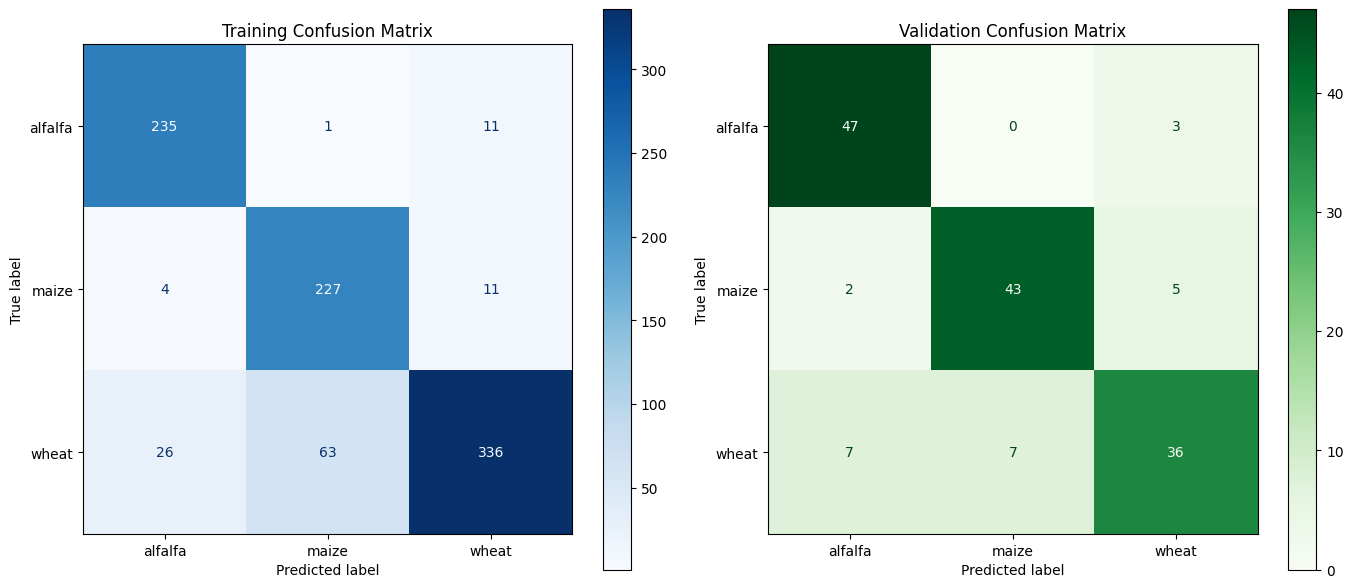


==================== TEST SET PREDICTIONS ====================


,sample_id,predicted_target
0,r2_20ee84e282b608b9,maize
1,r2_3f59edc42ae9243f,maize
2,r2_40d69d894813f204,wheat
3,r2_278ee6f93f7b31ef,maize
4,r2_653d9a22fd070481,maize
5,r2_7fbb4905ffbf8d7e,maize
6,r2_e261f65f34789124,alfalfa
7,r2_53bebc7590cf779d,maize
8,r2_ee7d113fc7f4c99e,maize
9,r2_b01ab6e02585518e,maize


In [18]:
# 1. Initialize the best performing Quantum Feature Map and Kernel (reps=1)
best_feature_map = PauliFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="full")
best_kernel = FidelityStatevectorKernel(feature_map=best_feature_map, auto_clear_cache=False, enforce_psd=True)

# Calculate precomputed kernels
print("Calculating Quantum Kernels...")
K_train_best = best_kernel.evaluate(X_train_pca[:, :4])
K_val_best = best_kernel.evaluate(X_val_pca[:, :4], X_train_pca[:, :4])
K_test_best = best_kernel.evaluate(X_test_pca[:, :4], X_train_pca[:, :4])

# 2. Train the best QSVC model (C=1.0)
best_qsvc = QSVC(
    quantum_kernel="precomputed", C=1.0, class_weight="balanced",
    probability=False, random_state=42,
)
best_qsvc.fit(K_train_best, y_train)

# 3. Generate Predictions
train_pred = best_qsvc.predict(K_train_best)
val_pred = best_qsvc.predict(K_val_best)
test_pred = best_qsvc.predict(K_test_best)

# Retrieve target category names from the LabelEncoder
target_names = list(label_encoder.classes_)

# --- Evaluation Reports ---
print("\n" + "="*20 + " TRAINING CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_train, train_pred, target_names=target_names))

print("\n" + "="*20 + " VALIDATION CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_val, val_pred, target_names=target_names))

# --- Confusion Matrices Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Train Confusion Matrix
cm_train = confusion_matrix(y_train, train_pred)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=target_names)
disp_train.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Training Confusion Matrix")

# Validation Confusion Matrix
cm_val = confusion_matrix(y_val, val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=target_names)
disp_val.plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Validation Confusion Matrix")

plt.tight_layout()
plt.show()

# --- Test Set Predictions ---
print("\n" + "="*20 + " TEST SET PREDICTIONS " + "="*20)
# Map encoded predictions back to original class labels
test_pred_labels = label_encoder.inverse_transform(test_pred)
df_test_results = pd.DataFrame({
    'sample_id': df_test['sample_id'],
    'predicted_target': test_pred_labels
})
display(df_test_results.head(10))

In [19]:
val_accuracies = []
pauli_f1 = []

# Best parameters discovered: reps=2, feature_dimension=8, C=1.0
for seed in seeds:
    print(f"Evaluating Seed {seed}...")

    # Initialize the feature map & kernel
    feature_map = PauliFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="full")
    kernel = FidelityStatevectorKernel(feature_map=feature_map, auto_clear_cache=False, enforce_psd=True)

    # Calculate kernels for train and validation sets
    K_train_seed = kernel.evaluate(X_train_pca)
    K_val_seed = kernel.evaluate(X_val_pca, X_train_pca)

    # Fit QSVC
    qsvc_seed = QSVC(
        quantum_kernel=kernel, C=1.0, class_weight="balanced",
        probability=False, random_state=seed,
    )
    qsvc_seed.fit(X_train_pca, y_train)

    # Predict & evaluate on validation set
    val_pred_seed = qsvc_seed.predict(X_val_pca)

    acc = accuracy_score(y_val, val_pred_seed)
    f1 = f1_score(y_val, val_pred_seed, average='weighted')

    val_accuracies.append(acc)
    pauli_f1.append(f1)
    print(f"Seed {seed} | Validation Accuracy: {acc:.4f} | Validation F1: {f1:.4f}")

print("\n" + "="*20 + " MULTI-SEED METRICS SUMMARY " + "="*20)
print(f"Validation Accuracy: {np.mean(val_accuracies):.4f} ± {np.std(val_accuracies):.4f}")
print(f"Validation F1-Score: {np.mean(pauli_f1):.4f} ± {np.std(pauli_f1):.4f}")

Evaluating Seed 0...


/tmp/ipykernel_513/1138906264.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation.pauli_feature_map.PauliFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the pauli_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = PauliFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="full")


Seed 0 | Validation Accuracy: 0.8533 | Validation F1: 0.8514
Evaluating Seed 1...


/tmp/ipykernel_513/1138906264.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation.pauli_feature_map.PauliFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the pauli_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = PauliFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="full")


Seed 1 | Validation Accuracy: 0.8533 | Validation F1: 0.8514
Evaluating Seed 2...


/tmp/ipykernel_513/1138906264.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation.pauli_feature_map.PauliFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the pauli_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = PauliFeatureMap(feature_dimension=n_qubits, reps=1, entanglement="full")


Seed 2 | Validation Accuracy: 0.8533 | Validation F1: 0.8514

==================== MULTI-SEED METRICS SUMMARY ====================
Validation Accuracy: 0.8533 ± 0.0000
Validation F1-Score: 0.8514 ± 0.0000


# **QSVM : ZFeatureMap**

In [20]:
from sklearn.preprocessing import LabelEncoder

df_train = pd.read_csv("train.csv")

# Define the feature columns present in the dataset (excluding identifier and target)
feature_columns = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']

X_train = df_train[feature_columns].to_numpy(dtype=float)
X_test = df_test[feature_columns].to_numpy(dtype=float)
X_val = df_val[feature_columns].to_numpy(dtype=float)

# Target: Use the categorical crop type column for classification
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train['target'].values)
y_val = label_encoder.transform(df_val['target'].values)
# Removed test set target encoding since df_test doesn't have a 'target' column

# Preprocessing features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=pca_components, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Train features shape (X_train): {X_train_pca.shape}")
print(f"Train targets shape (y_train): {y_train.shape}")

Train features shape (X_train): (914, 8)
Train targets shape (y_train): (914,)


Calculating Quantum Kernels...


/tmp/ipykernel_513/4036480464.py:2: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  best_feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)



==================== TRAINING CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.89      0.91      0.90       247
       maize       0.72      0.95      0.82       242
       wheat       0.93      0.74      0.82       425

    accuracy                           0.84       914
   macro avg       0.85      0.87      0.85       914
weighted avg       0.86      0.84      0.84       914


==================== VALIDATION CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.89      0.94      0.91        50
       maize       0.82      0.94      0.88        50
       wheat       0.90      0.72      0.80        50

    accuracy                           0.87       150
   macro avg       0.87      0.87      0.86       150
weighted avg       0.87      0.87      0.86       150



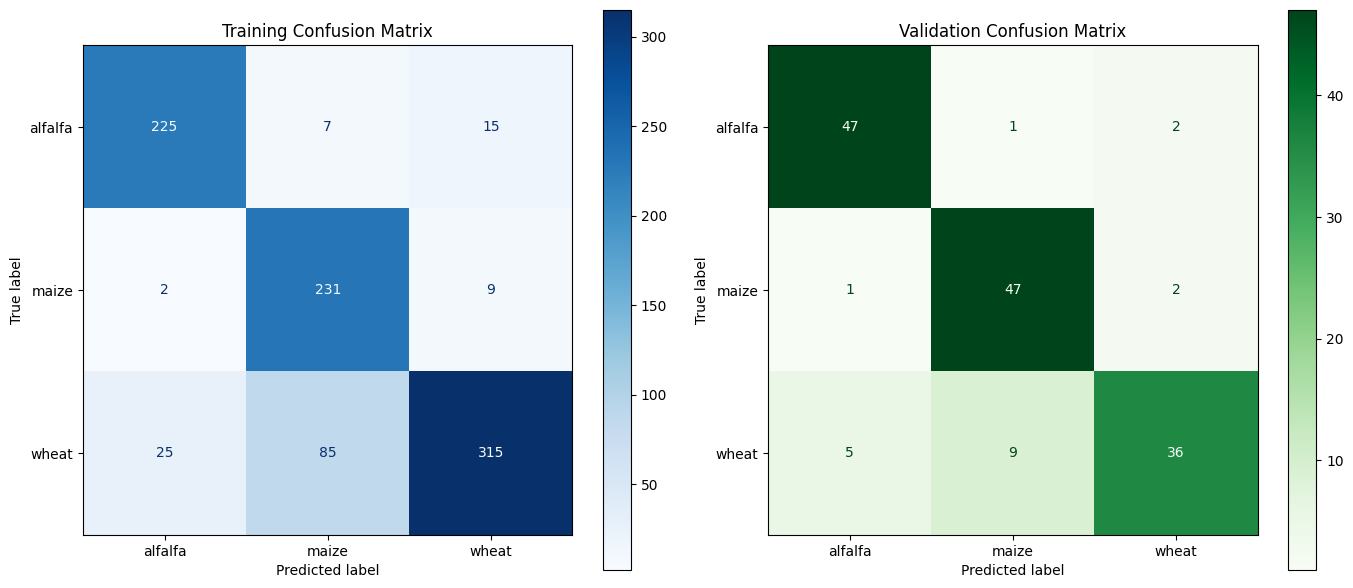


==================== TEST SET PREDICTIONS ====================


,sample_id,predicted_target
0,r2_20ee84e282b608b9,maize
1,r2_3f59edc42ae9243f,maize
2,r2_40d69d894813f204,wheat
3,r2_278ee6f93f7b31ef,maize
4,r2_653d9a22fd070481,maize
5,r2_7fbb4905ffbf8d7e,maize
6,r2_e261f65f34789124,alfalfa
7,r2_53bebc7590cf779d,maize
8,r2_ee7d113fc7f4c99e,maize
9,r2_b01ab6e02585518e,maize


In [21]:
# 1. Initialize ZFeatureMap and Kernel (reps=2)
best_feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)
best_kernel = FidelityStatevectorKernel(feature_map=best_feature_map, auto_clear_cache=False, enforce_psd=True)

# Calculate precomputed kernels using first 4 dimensions of the PCA features
print("Calculating Quantum Kernels...")
K_train_best = best_kernel.evaluate(X_train_pca[:, :4])
K_val_best = best_kernel.evaluate(X_val_pca[:, :4], X_train_pca[:, :4])
K_test_best = best_kernel.evaluate(X_test_pca[:, :4], X_train_pca[:, :4])

# 2. Train the best QSVC model (C=1.0)
best_qsvc = QSVC(
    quantum_kernel="precomputed", C=1.0, class_weight="balanced",
    probability=False, random_state=42,
)
best_qsvc.fit(K_train_best, y_train)

# 3. Generate Predictions
train_pred = best_qsvc.predict(K_train_best)
val_pred = best_qsvc.predict(K_val_best)
test_pred = best_qsvc.predict(K_test_best)

# Retrieve target category names from the LabelEncoder
target_names = list(label_encoder.classes_)

# --- Evaluation Reports ---
print("\n" + "="*20 + " TRAINING CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_train, train_pred, target_names=target_names))

print("\n" + "="*20 + " VALIDATION CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_val, val_pred, target_names=target_names))

# --- Confusion Matrices Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Train Confusion Matrix
cm_train = confusion_matrix(y_train, train_pred)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=target_names)
disp_train.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Training Confusion Matrix")

# Validation Confusion Matrix
cm_val = confusion_matrix(y_val, val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=target_names)
disp_val.plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Validation Confusion Matrix")

plt.tight_layout()
plt.show()

# --- Test Set Predictions ---
print("\n" + "="*20 + " TEST SET PREDICTIONS " + "="*20)
test_pred_labels = label_encoder.inverse_transform(test_pred)
df_test_results = pd.DataFrame({
    'sample_id': df_test['sample_id'],
    'predicted_target': test_pred_labels
})
display(df_test_results.head(10))

In [22]:
val_accuracies = []
zfeature_f1 = []

# Best parameters discovered: reps=2, feature_dimension=8, C=1.0
for seed in seeds:
    print(f"Evaluating Seed {seed}...")

    # Initialize the feature map & kernel
    feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)
    kernel = FidelityStatevectorKernel(feature_map=feature_map, auto_clear_cache=False, enforce_psd=True)

    # Calculate kernels for train and validation sets
    K_train_seed = kernel.evaluate(X_train_pca)
    K_val_seed = kernel.evaluate(X_val_pca, X_train_pca)

    # Fit QSVC
    qsvc_seed = QSVC(
        quantum_kernel=kernel, C=1.0, class_weight="balanced",
        probability=False, random_state=seed,
    )
    qsvc_seed.fit(X_train_pca, y_train)

    # Predict & evaluate on validation set
    val_pred_seed = qsvc_seed.predict(X_val_pca)

    acc = accuracy_score(y_val, val_pred_seed)
    f1 = f1_score(y_val, val_pred_seed, average='weighted')

    val_accuracies.append(acc)
    zfeature_f1.append(f1)
    print(f"Seed {seed} | Validation Accuracy: {acc:.4f} | Validation F1: {f1:.4f}")

print("\n" + "="*20 + " MULTI-SEED METRICS SUMMARY " + "="*20)
print(f"Validation Accuracy: {np.mean(val_accuracies):.4f} ± {np.std(val_accuracies):.4f}")
print(f"Validation F1-Score: {np.mean(zfeature_f1):.4f} ± {np.std(zfeature_f1):.4f}")

Evaluating Seed 0...


/tmp/ipykernel_513/3245682874.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)


Seed 0 | Validation Accuracy: 0.8600 | Validation F1: 0.8563
Evaluating Seed 1...


/tmp/ipykernel_513/3245682874.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)


Seed 1 | Validation Accuracy: 0.8600 | Validation F1: 0.8563
Evaluating Seed 2...


/tmp/ipykernel_513/3245682874.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._z_feature_map.ZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the z_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZFeatureMap(feature_dimension=n_qubits, reps=2)


Seed 2 | Validation Accuracy: 0.8600 | Validation F1: 0.8563

==================== MULTI-SEED METRICS SUMMARY ====================
Validation Accuracy: 0.8600 ± 0.0000
Validation F1-Score: 0.8563 ± 0.0000


# **QSVM : ZZFeatureMap**

In [23]:
from sklearn.preprocessing import LabelEncoder

df_train = pd.read_csv("train.csv")

# Define the feature columns present in the dataset (excluding identifier and target)
feature_columns = ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8A', 'B9', 'B11', 'B12', 'NDVI']

X_train = df_train[feature_columns].to_numpy(dtype=float)
X_test = df_test[feature_columns].to_numpy(dtype=float)
X_val = df_val[feature_columns].to_numpy(dtype=float)

# Target: Use the categorical crop type column for classification
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(df_train['target'].values)
y_val = label_encoder.transform(df_val['target'].values)
# Removed test set target encoding since df_test doesn't have a 'target' column

# Preprocessing features
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=pca_components, svd_solver="full")
X_train_pca = pca.fit_transform(X_train_scaled)
X_val_pca = pca.transform(X_val_scaled)
X_test_pca = pca.transform(X_test_scaled)

print(f"Train features shape (X_train): {X_train_pca.shape}")
print(f"Train targets shape (y_train): {y_train.shape}")

Train features shape (X_train): (914, 8)
Train targets shape (y_train): (914,)


Calculating Quantum Kernels...


/tmp/ipykernel_513/85910870.py:2: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  best_feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=2, entanglement="linear")



==================== TRAINING CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.90      0.95      0.92       247
       maize       0.87      0.95      0.91       242
       wheat       0.95      0.87      0.91       425

    accuracy                           0.91       914
   macro avg       0.91      0.92      0.91       914
weighted avg       0.92      0.91      0.91       914


==================== VALIDATION CLASSIFICATION REPORT ====================
              precision    recall  f1-score   support

     alfalfa       0.87      0.92      0.89        50
       maize       0.81      0.86      0.83        50
       wheat       0.86      0.76      0.81        50

    accuracy                           0.85       150
   macro avg       0.85      0.85      0.85       150
weighted avg       0.85      0.85      0.85       150



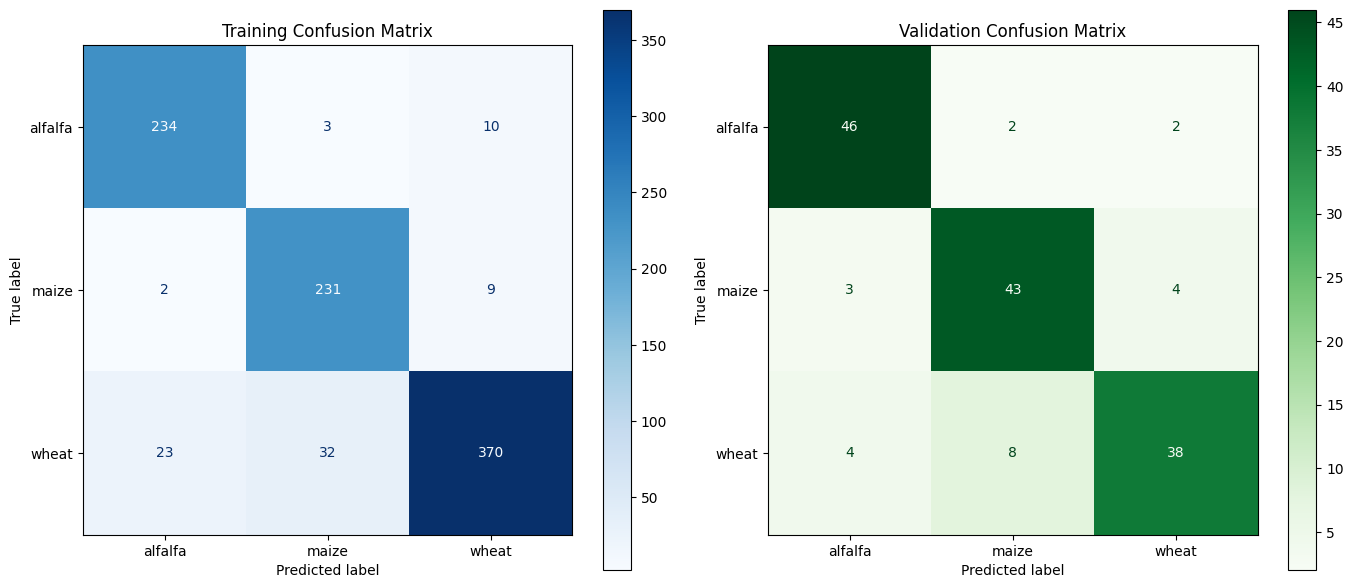


==================== TEST SET PREDICTIONS ====================


,sample_id,predicted_target
0,r2_20ee84e282b608b9,maize
1,r2_3f59edc42ae9243f,maize
2,r2_40d69d894813f204,wheat
3,r2_278ee6f93f7b31ef,maize
4,r2_653d9a22fd070481,maize
5,r2_7fbb4905ffbf8d7e,maize
6,r2_e261f65f34789124,wheat
7,r2_53bebc7590cf779d,maize
8,r2_ee7d113fc7f4c99e,maize
9,r2_b01ab6e02585518e,maize


In [24]:
# 1. Initialize the best performing Quantum Feature Map and Kernel (reps=1)
best_feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=2, entanglement="linear")
best_kernel = FidelityStatevectorKernel(feature_map=best_feature_map, auto_clear_cache=False, enforce_psd=True)

# Calculate precomputed kernels
print("Calculating Quantum Kernels...")
K_train_best = best_kernel.evaluate(X_train_pca)
K_val_best = best_kernel.evaluate(X_val_pca, X_train_pca)
K_test_best = best_kernel.evaluate(X_test_pca, X_train_pca)

# 2. Train the best QSVC model (C=1.0)
best_qsvc = QSVC(
    quantum_kernel="precomputed", C=1.0, class_weight="balanced",
    probability=False, random_state=42,
)
best_qsvc.fit(K_train_best, y_train)

# 3. Generate Predictions
train_pred = best_qsvc.predict(K_train_best)
val_pred = best_qsvc.predict(K_val_best)
test_pred = best_qsvc.predict(K_test_best)

# Retrieve target category names from the LabelEncoder
target_names = list(label_encoder.classes_)

# --- Evaluation Reports ---
print("\n" + "="*20 + " TRAINING CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_train, train_pred, target_names=target_names))

print("\n" + "="*20 + " VALIDATION CLASSIFICATION REPORT " + "="*20)
print(classification_report(y_val, val_pred, target_names=target_names))

# --- Confusion Matrices Plotting ---
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Train Confusion Matrix
cm_train = confusion_matrix(y_train, train_pred)
disp_train = ConfusionMatrixDisplay(confusion_matrix=cm_train, display_labels=target_names)
disp_train.plot(ax=axes[0], cmap="Blues", values_format="d")
axes[0].set_title("Training Confusion Matrix")

# Validation Confusion Matrix
cm_val = confusion_matrix(y_val, val_pred)
disp_val = ConfusionMatrixDisplay(confusion_matrix=cm_val, display_labels=target_names)
disp_val.plot(ax=axes[1], cmap="Greens", values_format="d")
axes[1].set_title("Validation Confusion Matrix")

plt.tight_layout()
plt.show()

# --- Test Set Predictions ---
print("\n" + "="*20 + " TEST SET PREDICTIONS " + "="*20)
# Map encoded predictions back to original class labels
test_pred_labels = label_encoder.inverse_transform(test_pred)
df_test_results = pd.DataFrame({
    'sample_id': df_test['sample_id'],
    'predicted_target': test_pred_labels
})
display(df_test_results.head(10))

In [25]:
val_accuracies = []
zzfeature_f1 = []

# Best parameters discovered: reps=2, feature_dimension=8, C=1.0
for seed in seeds:
    print(f"Evaluating Seed {seed}...")

    # Initialize the feature map & kernel
    feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=2, entanglement="linear")
    kernel = FidelityStatevectorKernel(feature_map=feature_map, auto_clear_cache=False, enforce_psd=True)

    # Calculate kernels for train and validation sets
    K_train_seed = kernel.evaluate(X_train_pca)
    K_val_seed = kernel.evaluate(X_val_pca, X_train_pca)

    # Fit QSVC
    qsvc_seed = QSVC(
        quantum_kernel=kernel, C=1.0, class_weight="balanced",
        probability=False, random_state=seed,
    )
    qsvc_seed.fit(X_train_pca, y_train)

    # Predict & evaluate on validation set
    val_pred_seed = qsvc_seed.predict(X_val_pca)

    acc = accuracy_score(y_val, val_pred_seed)
    f1 = f1_score(y_val, val_pred_seed, average='weighted')

    val_accuracies.append(acc)
    zzfeature_f1.append(f1)
    print(f"Seed {seed} | Validation Accuracy: {acc:.4f} | Validation F1: {f1:.4f}")

print("\n" + "="*20 + " MULTI-SEED METRICS SUMMARY " + "="*20)
print(f"Validation Accuracy: {np.mean(val_accuracies):.4f} ± {np.std(val_accuracies):.4f}")
print(f"Validation F1-Score: {np.mean(zzfeature_f1):.4f} ± {np.std(zzfeature_f1):.4f}")

Evaluating Seed 0...


/tmp/ipykernel_513/3795744623.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=2, entanglement="linear")


Seed 0 | Validation Accuracy: 0.8467 | Validation F1: 0.8456
Evaluating Seed 1...


/tmp/ipykernel_513/3795744623.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=2, entanglement="linear")


Seed 1 | Validation Accuracy: 0.8467 | Validation F1: 0.8456
Evaluating Seed 2...


/tmp/ipykernel_513/3795744623.py:9: DeprecationWarning: The class ``qiskit.circuit.library.data_preparation._zz_feature_map.ZZFeatureMap`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the zz_feature_map function as a replacement. Note that this will no longer return a BlueprintCircuit, but just a plain QuantumCircuit.
  feature_map = ZZFeatureMap(feature_dimension=n_qubits, reps=2, entanglement="linear")


Seed 2 | Validation Accuracy: 0.8467 | Validation F1: 0.8456

==================== MULTI-SEED METRICS SUMMARY ====================
Validation Accuracy: 0.8467 ± 0.0000
Validation F1-Score: 0.8456 ± 0.0000


# **Plot**

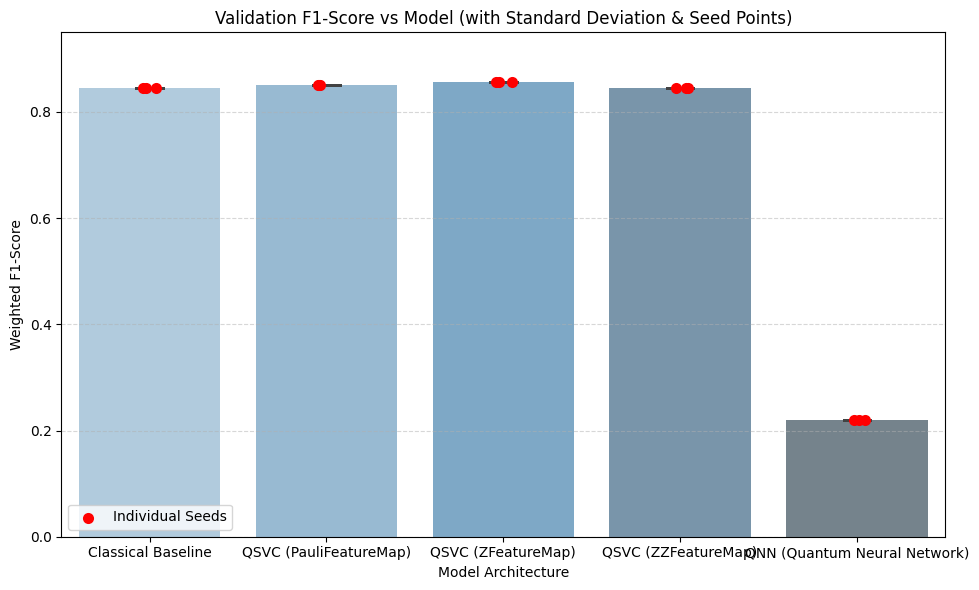

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

qnn_f1 = [0.2191, 0.2191, 0.2191]

# Re-create clean pandas DataFrame mapping each model and seed explicitly
plot_data = []

# We have 3 seeds (0, 1, 2) evaluated. Index each list to get the scalar F1-score for that seed.
for i, seed in enumerate([0, 1, 2]):
    plot_data.append({"Model": "Classical Baseline", "Seed": f"Seed {seed}", "F1-Score": baseline_f1[i]})
    plot_data.append({"Model": "QSVC (PauliFeatureMap)", "Seed": f"Seed {seed}", "F1-Score": pauli_f1[i]})
    plot_data.append({"Model": "QSVC (ZFeatureMap)", "Seed": f"Seed {seed}", "F1-Score": zfeature_f1[i]})
    plot_data.append({"Model": "QSVC (ZZFeatureMap)", "Seed": f"Seed {seed}", "F1-Score": zzfeature_f1[i]})
    plot_data.append({"Model": "QNN (Quantum Neural Network)", "Seed": f"Seed {seed}", "F1-Score": qnn_f1[i]})

df_plot = pd.DataFrame(plot_data)

# Plot F1-score vs Model with mean, standard deviation (error bars), and individual seeds as points
plt.figure(figsize=(10, 6))

# Bar plot showing the mean and standard deviation as error bars
sns.barplot(
    x="Model", y="F1-Score", hue="Model", data=df_plot,
    errorbar="sd", capsize=0.15, palette="Blues_d", alpha=0.7, err_kws={'linewidth': 2}, legend=False
)

# Swarm/Strip plot overlay to show individual seed values as points
sns.stripplot(
    x="Model", y="F1-Score", data=df_plot,
    color="red", size=8, jitter=0.05, label="Individual Seeds"
)

plt.title("Validation F1-Score vs Model (with Standard Deviation & Seed Points)")
plt.ylabel("Weighted F1-Score")
plt.xlabel("Model Architecture")
plt.ylim(0.0, 0.95)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Prevent duplicate legend items from strip plot
handles, labels = plt.gca().get_legend_handles_labels()
by_label = dict(zip(labels, handles))
plt.legend(by_label.values(), by_label.keys(), loc="lower left")

plt.tight_layout()
plt.show()